In [ ]:
import sys
from pathlib import Path

# Cherche le dossier racine du projet (BDS_Fault_Detection) pour faire les imports depuis Sources/
dossier = Path().resolve()
for parent in (dossier, *dossier.parents):
    if "BDS_Fault_Detection" in parent.name:
        RACINE = parent
sys.path.insert(0, str(RACINE))

# Importation des fonctions du projet (dossier Sources/). Attention de l'ordre d'importation  !
from Sources import data, features, config

import numpy as np
import keras
import matplotlib.pyplot as plt

I0000 00:00:1795620107.155506   11982 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# === Chargement du modèle entrainé === #
Fitted_Model = keras.models.load_model(RACINE / "Sources" / "Fitted_models" / "DAE_fitted.keras")

In [ ]:
def construire_fenetres_brutes_test(nom, canal="DE", duree=config.DUREE_FENETRE, recouvrement=0.5):
    s = data.charger(nom, canaux=(canal,))
    fenetres = features.fenetrer(s[canal], s["fs"], duree=duree, recouvrement=recouvrement)
    return np.array(fenetres, dtype=np.float32)

def score_mse(modele, X):
    Xr = modele.predict(X[..., None], verbose=0)[..., 0]
    return ((X - Xr) ** 2).mean(axis=1)

def Tester_signal(modele, input, seuil):
    score = score_mse(modele, input)
    Nb_Defaut = (score > seuil).sum()
    Nb_Sain = (score < seuil).sum()
    print(f"Pourcentage de chance d'être un défaut : {Nb_Defaut/(Nb_Sain+Nb_Defaut)*100:.2f}%")
    plt.plot(score, label="Signal testé")
    plt.axhline(seuil, color="black", ls="--", lw=1, label="seuil d'alarme")
    plt.title("Score d'anomalie au cours du temps")
    plt.xlabel("fenêtre du signal"); plt.ylabel("MSE de reconstruction")
    plt.legend(); plt.show()

Pourcentage de chance d'être un défaut : 100.00%


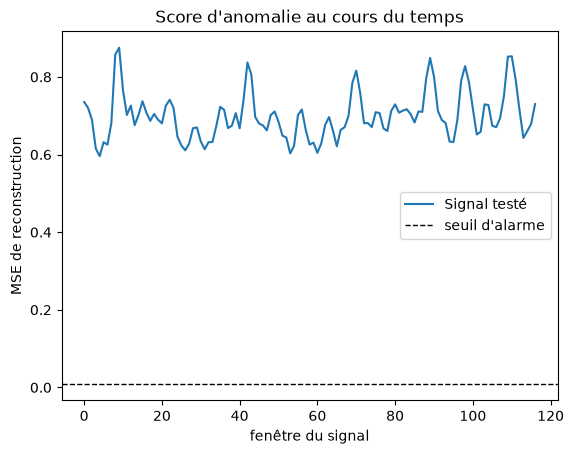

In [4]:
import joblib
pack = joblib.load(RACINE / "Sources" / "Fitted_models" / "DAE_params.joblib")
seuil, taille = pack["seuil"], pack["taille_fenetre"]

# Normal_L0, 12kDE_B021_L1, 12kDE_IR007_L3, 12kFE_IR007_L0, 12kFE_OR007at12_L0
SB_test = construire_fenetres_brutes_test("12kDE_B021_L1", canal="FE")

assert SB_test.shape[1] == taille, \
    f"fenêtres de {SB_test.shape[1]} éch., modèle entraîné sur {taille} (vérifier duree et fs)"
SB_test_norm = features.standardiser_par_fenetre(SB_test)   # même règle qu'à l'entraînement, AUCUN fit

Tester_signal(Fitted_Model, SB_test_norm, seuil)

Ici, on a testé l'enregistrement d'un Auto-Encodeur entraîné, et ses paramètres associés pour les réutiliser.  
Un test simple de fichier a été mis en place pour vérifier son fonctionnement, mais un problème est apparu :  
Lorsqu'on teste un fichier où un défaut est sur le roulement moteur (DE), et qu'on analyse les signaux du roulement ventilateur (FE), on constate qu'un défaut est détecté, alors qu'il n'y a pas de défaut sur le roulement FE !  
C'est le cas présenté dans la cellule précédente :   
- 12k**DE**_B021_L1     >> fichier avec un défaut côté moteur    
- canal="**FE**"    >> Analyse du canal ventilateur  

Les vibrations du défaut sur le roulement DE, sont également ressenties dans le signal FE, car les vibrations se propagent dans le montage.
Dans le notebook suivant, l'objectif sera d'identifier lequel des roulements a réellement un défaut.